<a href="https://colab.research.google.com/github/keikezon/FIAP-IA-para-devs/blob/master/An%C3%A1lise_de_Pureza_de_Etanol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

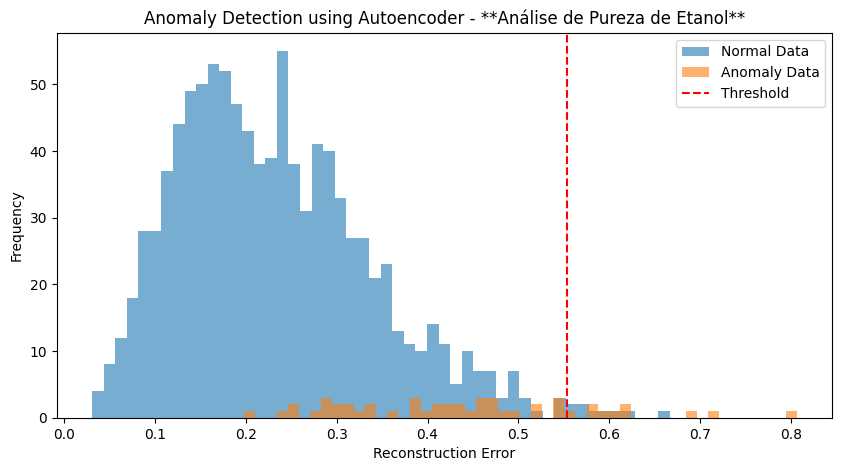

In [1]:
!pip install torch

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(0)
normal_data = np.random.normal(7, 0.5, (1000, 10))
anomaly_data_low = np.random.normal(3, 0.5, (25, 10))
anomaly_data_high = np.random.normal(11, 0.5, (25, 10))

data = np.concatenate([normal_data, anomaly_data_low, anomaly_data_high], axis=0)
data = torch.tensor(data, dtype=torch.float32)


class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(10, 6),
            nn.ReLU(),
            nn.Linear(6, 3)
        )
        self.decoder = nn.Sequential(
            nn.Linear(3, 6),
            nn.ReLU(),
            nn.Linear(6, 10)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 100
for epoch in range(epochs):
    output = model(data)
    loss = criterion(output, data)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


with torch.no_grad():
    reconstructed_data = model(data)
    mse = ((reconstructed_data - data) ** 2).mean(axis=1)


threshold = mse[:1000].mean() + 3 * mse[:1000].std()
anomalies = mse > threshold


plt.figure(figsize=(10,5))
plt.hist(mse[:1000], bins=50, alpha=0.6, label="Normal Data")
plt.hist(mse[1000:], bins=50, alpha=0.6, label="Anomaly Data")
plt.axvline(threshold, color='red', linestyle='--', label="Threshold")
plt.legend()
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.title("Anomaly Detection using Autoencoder - **Análise de Pureza de Etanol**")
plt.show()

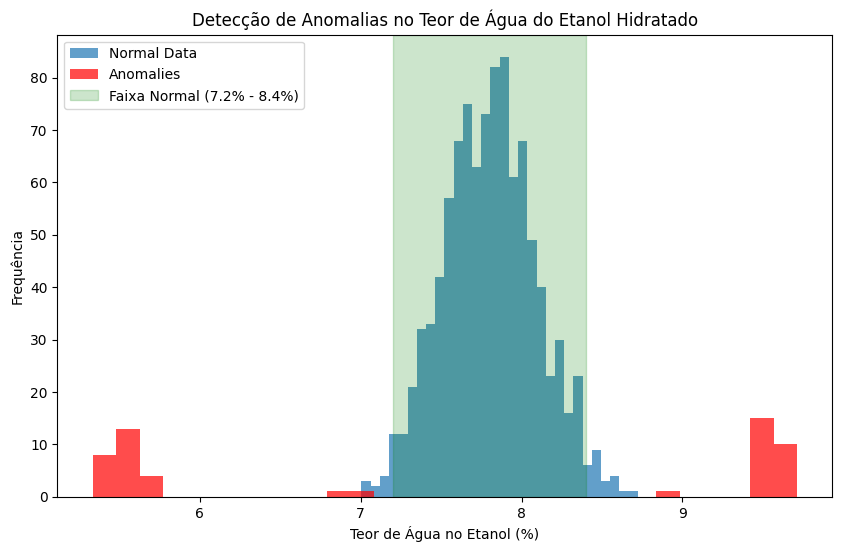

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

np.random.seed(42)

# Gerando dados simulados de teor de água
normal_water_content = np.random.normal(7.8, 0.3, 1000)
anomaly_water_content = np.concatenate([
    np.random.normal(9.5, 0.1, 25),
    np.random.normal(5.5, 0.1, 25)
])

# Combinando os dados
water_content_data = np.concatenate([normal_water_content, anomaly_water_content]).reshape(-1, 1)

# Aplicando o modelo de detecção de anomalias
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
model.fit(water_content_data)
predictions = model.predict(water_content_data)

normal_values = water_content_data[predictions == 1]
anomaly_values = water_content_data[predictions == -1]

# Faixa esperada de pureza do etanol hidratado
normal_range_min, normal_range_max = 7.2, 8.4

# Visualização dos resultados
plt.figure(figsize=(10, 6))
plt.hist(normal_values, bins=30, alpha=0.7, label="Normal Data")
plt.hist(anomaly_values, bins=30, alpha=0.7, color="red", label="Anomalies")
plt.axvspan(normal_range_min, normal_range_max, color="green", alpha=0.2, label="Faixa Normal (7.2% - 8.4%)")
plt.xlabel("Teor de Água no Etanol (%)")
plt.ylabel("Frequência")
plt.title("Detecção de Anomalias no Teor de Água do Etanol Hidratado")
plt.legend()
plt.show()